In [ ]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_12/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# 12.1. PatchTST: токен как отрезок

Поточечный трансформер на рядах проигрывает линейной модели: в статье Zeng et al. одна матрица `L → H`
обошла Informer, Autoformer и FEDformer почти на всех бенчмарках. Причина не обязательно в энкодере: каждая
точка ряда — отдельный токен, и внимание может сравнивать только величины, а не форму.

PatchTST (Nie et al., 2023) меняет вход, а не механизм: токеном становится отрезок ряда. Энкодер остаётся
прежним, но сравнивает он уже куски по 16 значений — наклон, кривизну и уровень одновременно.

Разбираем:
- почему скалярный токен ограничивает внимание (арифметика, не интуиция);
- патчинг: сколько токенов получается и во сколько раз дешевле карта внимания;
- абляцию `patch_len=1` — та же архитектура, повёрнутая обратно в поточечную;
- независимость каналов и RevIN.

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from datasetsforecast.long_horizon import LongHorizon
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from neuralforecast import NeuralForecast
from neuralforecast.models import DLinear, PatchTST, VanillaTransformer
from utilsforecast.evaluation import evaluate
from utilsforecast.losses import mae, mape

warnings.simplefilter("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "lightning_fabric"]:
    logging.getLogger(name).setLevel(logging.ERROR)
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

SEED = 1
ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
TRAINER_KW = dict(accelerator=ACCELERATOR, enable_progress_bar=True, enable_model_summary=False, logger=False)

In [2]:
def score(cv):
    """MAE и MAPE каждой модели, усреднённые по окнам кросс-валидации."""
    models = [c for c in cv.columns if c not in ("unique_id", "ds", "cutoff", "y")]
    res = evaluate(cv, metrics=[mae, mape], models=models)
    return res.groupby("metric")[models].mean().T.round({"mae": 3, "mape": 4}).sort_values("mae")


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def box(ax, x, y, w, h, text, fc="#eef3fb", fs=9):
    """Прямоугольник со скруглёнными углами и подписью — для схем архитектур."""
    ax.add_patch(
        FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec="#3b5bdb", lw=1.2)
    )
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, linespacing=1.35)


def arrow(ax, xy_from, xy_to, color="#495057"):
    ax.add_patch(
        FancyArrowPatch(xy_from, xy_to, arrowstyle="-|>", mutation_scale=11, lw=1.1, color=color, shrinkA=0, shrinkB=0)
    )

## Данные и постановка

ETTm2 — семь рядов электрического трансформатора (температура масла `OT` и шесть нагрузок), шаг 15 минут.
Горизонт `h=96` (сутки), `input_size=336` (3.5 суток), три окна кросс-валидации и фиксированный бюджет
обучения — `100` шагов для линейных моделей и `300` для трансформеров.

In [3]:
Y_df, _, _ = LongHorizon.load(directory="../data", group="ETTm2")
Y_df["ds"] = pd.to_datetime(Y_df["ds"])

H, L, N_WINDOWS, LR = 96, 336, 3, 1e-3
LINEAR_STEPS, TRANSFORMER_STEPS = 100, 300

common = dict(h=H, input_size=L, learning_rate=LR, random_seed=SEED, **TRAINER_KW)
linear_kw = {**common, "max_steps": LINEAR_STEPS}
transformer_kw = {**common, "max_steps": TRANSFORMER_STEPS}
print("точек:", len(Y_df), "| рядов:", Y_df["unique_id"].nunique())

точек: 403200 | рядов: 7


## 1. Почему скалярный токен ограничивает внимание

В поточечном трансформере $i$-й токен — это значение ряда в момент $i$: $e_i = y_i w$. Запрос и ключ
получаются из него линейно, значит $q_i$ и $k_j$ — это одно и то же число $y$, умноженное на разные векторы.

Отсюда следствие для матрицы скоров $S_{ij} = q_i \cdot k_j$: она построена из одного числа на строку, и её
ранг не зависит от длины окна. У матрицы 336×336 всего две независимые строки — «константа» и «значение».

In [4]:
rng = np.random.default_rng(0)
window = Y_df.query("unique_id == 'OT'")["y"].to_numpy()[-L:]
y = (window - window.mean()) / window.std()

Q = np.outer(y, rng.normal(size=8)) + rng.normal(size=8)  # запросы: линейная функция от токенов
K = np.outer(y, rng.normal(size=8)) + rng.normal(size=8)  # ключи: тоже
S = Q @ K.T

print("окно:", y.size, "| матрица скоров:", S.shape, "| её ранг:", np.linalg.matrix_rank(S))

окно: 336 | матрица скоров: (336, 336) | её ранг: 2


Ранг равен двум. Все строки — комбинации двух векторов, поэтому **все запросы ранжируют ключи одинаково —
по величине $y_j$**, с точностью до направления: внимание может «выбрать большие значения» или «выбрать
малые», но не может для каждого запроса сказать что-то своё. Разнообразие вносит только позиционное кодирование, то есть информация не из данных.

Вторая проблема нагляднее. У скалярных токенов нет формы: два отрезка по 16 точек — возрастающий
и убывающий — как наборы значений неразличимы.

In [5]:
rising = np.arange(1, 17, dtype=float)
falling = rising[::-1]

print("одинаковый набор значений:", np.array_equal(np.sort(rising), np.sort(falling)))
print("среднее:", rising.mean(), falling.mean(), "| разброс:", round(rising.std(), 2), round(falling.std(), 2))

cos = rising @ falling / np.linalg.norm(rising) / np.linalg.norm(falling)
print(f"а как векторы они расходятся на {np.degrees(np.arccos(cos)):.0f}°")

одинаковый набор значений: True
среднее: 8.5 8.5 | разброс: 4.61 4.61
а как векторы они расходятся на 57°


Одинаковые среднее, разброс и набор значений — и противоположное направление. Поточечная токенизация эту
разницу выбрасывает. Патч её сохраняет: 16 подряд идущих значений — вектор, у которого есть направление.

## 2. Патчинг

Окно режется на перекрывающиеся отрезки длины `patch_len` с шагом `stride`. Каждый отрезок линейно проецируется
в `hidden_size` измерений и получает позиционный эмбеддинг. Дальше — обычный энкодер трансформера.

На картинке: сверху последние 336 точек `OT` с границами патчей, снизу — увеличенный фрагмент, где видно
перекрытие.

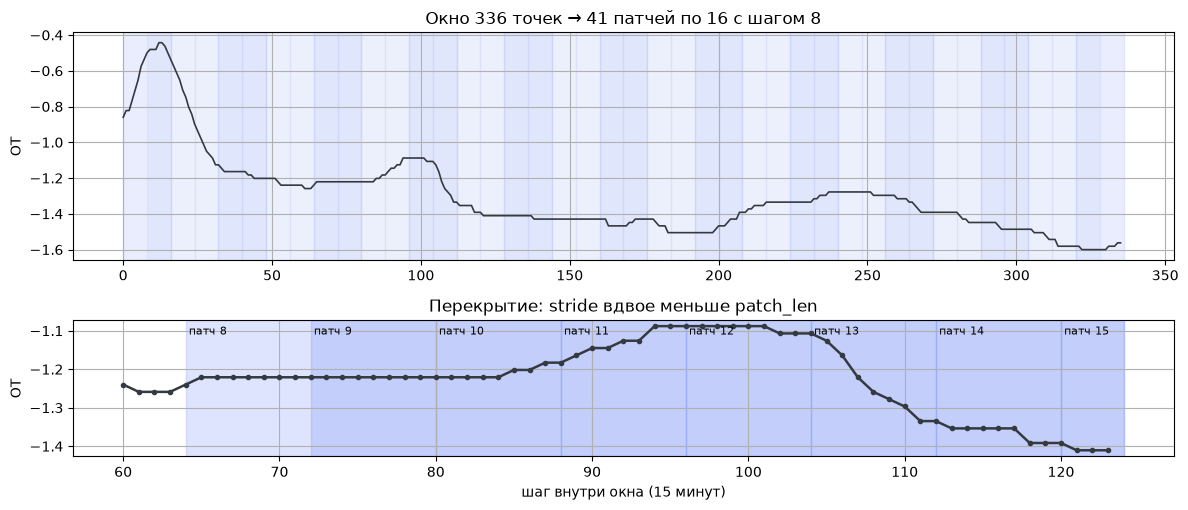

In [6]:
patch_len, stride = 16, 8
patches = np.lib.stride_tricks.sliding_window_view(window, patch_len)[::stride]
starts = np.arange(0, len(window) - patch_len + 1, stride)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 5.2), gridspec_kw={"height_ratios": [2, 1.2]})

ax1.plot(window, lw=1.2, color="#343a40")
for s in starts:
    ax1.axvspan(s, s + patch_len, color="#4c6ef5", alpha=0.12 if s % 32 == 0 else 0.05)
ax1.set(title=f"Окно {L} точек → {len(patches)} патчей по {patch_len} с шагом {stride}", xlabel="", ylabel="OT")

lo, hi = 60, 60 + 6 * stride + patch_len
ax2.plot(np.arange(lo, hi), window[lo:hi], lw=1.8, color="#343a40", marker="o", ms=3)
for s in starts:
    if lo <= s < hi:
        ax2.axvspan(max(s, lo), min(s + patch_len, hi), color="#4c6ef5", alpha=0.18)
        ax2.text(max(s, lo) + 0.2, window[lo:hi].max(), f"патч {s // stride}", fontsize=8, va="top")
ax2.set(xlabel="шаг внутри окна (15 минут)", ylabel="OT", title="Перекрытие: stride вдвое меньше patch_len")
plt.tight_layout();

41 патч вместо 336 точек. Соседние патчи перекрываются наполовину: токенов меньше, но ни один участок ряда
не выпадает из поля зрения.

Выигрыш не только в информации, но и в стоимости. Матрица внимания квадратична по числу токенов.

In [7]:
patching = pd.DataFrame({"patch_len": [1, 8, 16], "stride": [1, 4, 8]})
patching["токенов"] = (L - patching["patch_len"]) // patching["stride"] + 1
patching["элементов в карте"] = patching["токенов"] ** 2
patching["дешевле поточечной, раз"] = (L**2 / patching["элементов в карте"]).round(1)
patching

,patch_len,stride,токенов,элементов в карте,"дешевле поточечной, раз"
0,1,1,336,112896,1.0
1,8,4,83,6889,16.4
2,16,8,41,1681,67.2


При `patch_len=16` карта внимания меньше в 67 раз. В neuralforecast к окну ещё дописывается справа `stride`
копий последней точки (`padding_patch="end"`), и патчей выходит на один больше — 42, а не 41; на порядок
величин это не влияет. Именно квадрат по длине окна мешал трансформеру работать
с длинным контекстом.

Заодно патч разводит две вещи, которые поточечный токен склеивал: «сколько токенов» и «сколько времени покрывает
один токен». Длину контекста теперь можно менять, не меняя размер карты.

## 3. Устройство PatchTST

Схема: патчи проецируются в 128 измерений, энкодер из трёх слоёв их перемешивает, голова разворачивает
все токены в горизонт.

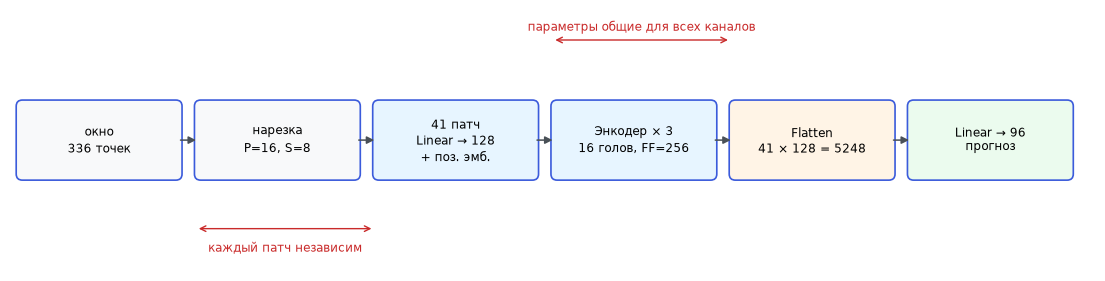

In [8]:
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.set(xlim=(0, 14), ylim=(0, 3.4))
ax.axis("off")

chain = [
    ("окно\n336 точек", "#f8f9fa"),
    ("нарезка\nP=16, S=8", "#f8f9fa"),
    ("41 патч\nLinear → 128\n+ поз. эмб.", "#e7f5ff"),
    ("Энкодер × 3\n16 голов, FF=256", "#e7f5ff"),
    ("Flatten\n41 × 128 = 5248", "#fff4e6"),
    ("Linear → 96\nпрогноз", "#ebfbee"),
]
xs = [0.1, 2.4, 4.7, 7.0, 9.3, 11.6]
for x, (text, fc) in zip(xs, chain):
    box(ax, x, 1.2, 2.1, 1.0, text, fc=fc, fs=8.5)
for x in xs[:-1]:
    arrow(ax, (x + 2.1, 1.7), (x + 2.3, 1.7))

ax.annotate("", xy=(4.7, 0.55), xytext=(2.4, 0.55), arrowprops=dict(arrowstyle="<->", lw=1, color="#c92a2a"))
ax.text(3.55, 0.25, "каждый патч независим", ha="center", fontsize=8.5, color="#c92a2a")
ax.annotate("", xy=(9.3, 3.0), xytext=(7.0, 3.0), arrowprops=dict(arrowstyle="<->", lw=1, color="#c92a2a"))
ax.text(8.15, 3.12, "параметры общие для всех каналов", ha="center", fontsize=8.5, color="#c92a2a");

На схеме — библиотечные значения по умолчанию, с учётом добавочного патча голова читает 42 × 128 = 5376 чисел.
Настройки отличаются от `VanillaTransformer`: три слоя энкодера вместо двух и шестнадцать голов вместо четырёх.
Это не подгонка — токенов стало в восемь раз меньше, и на меньшее их число модель может позволить себе
больше внимания. RevIN включён по умолчанию (`revin=True`) и разбирается ниже.

## 4. С чем сравниваем

DLinear — линейная планка: ряд раскладывается на тренд и остаток, у каждой части своя матрица `L → H`,
общая для всех рядов. `VanillaTransformer` —
поточечный трансформер, который патчинг и должен побить. Обе обучаются здесь заново, на том же бюджете.

In [9]:
t0 = time.time()
nf_dl = NeuralForecast(models=[DLinear(alias="DLinear", **linear_kw)], freq="15min")
cv_dl = nf_dl.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_dl = time.time() - t0
score(cv_dl)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
DLinear,0.188,0.2524


In [10]:
t0 = time.time()
nf_vt = NeuralForecast(models=[VanillaTransformer(alias="VanillaTransformer", **transformer_kw)], freq="15min")
cv_vt = nf_vt.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_vt = time.time() - t0
score(cv_vt)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
VanillaTransformer,0.214,0.2637


## 5. PatchTST

Та же постановка, те же окна, те же модели сравнения.

In [11]:
t0 = time.time()
nf_pt = NeuralForecast(models=[PatchTST(alias="PatchTST", **transformer_kw)], freq="15min")
cv_pt = nf_pt.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_pt = time.time() - t0
score(cv_pt)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

metric,mae,mape
PatchTST,0.206,0.2469


In [12]:
summary = pd.concat([score(cv_dl), score(cv_vt), score(cv_pt)]).sort_values("mae")
summary["параметров"] = summary.index.map(
    {"DLinear": n_params(nf_dl.models[0]), "VanillaTransformer": n_params(nf_vt.models[0]), "PatchTST": n_params(nf_pt.models[0])}
)
summary["обучение, с"] = summary.index.map({"DLinear": time_dl, "VanillaTransformer": time_vt, "PatchTST": time_pt})
summary.round(2)

metric,mae,mape,параметров,"обучение, с"
DLinear,0.19,0.25,64704,7.68
PatchTST,0.21,0.25,921187,23.30
VanillaTransformer,0.21,0.26,292449,67.72


Лучшая по MAE — DLinear (0.188). `PatchTST` (0.206) обходит `VanillaTransformer` (0.214), но до линейной
модели не дотягивает, хотя по MAPE у него лучший результат из трёх. Разрыв — единицы процентов, и это
ожидаемо: ряды гладкие и сильно автокоррелированные, линейного отображения окна в горизонт почти достаточно.
В статье выигрыш такой же неровный — на Weather и Traffic заметный, на ETT единицы процентов, местами ноль.

Сильнее модели различаются по стоимости. У `PatchTST` втрое больше параметров, чем у `VanillaTransformer`,
но обучается он почти втрое быстрее: 42 токена вместо 336 — это карта внимания в 64 раза меньше, и время
уходит не на параметры, а на неё.

## 6. Главная абляция: `patch_len=1`

Вся идея патчинга выражена одним параметром. Поставим `patch_len=1, stride=1` — патч станет одной точкой.
Архитектура не меняется: тот же энкодер, то же внимание, та же голова, только токенов снова 336.
Обе модели обучаются с нуля в одинаковых условиях.

In [13]:
t0 = time.time()
nf_p1 = NeuralForecast(
    models=[PatchTST(alias="PatchTST, patch_len=1", patch_len=1, stride=1, **transformer_kw)], freq="15min"
)
cv_p1 = nf_p1.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_p1 = time.time() - t0

pd.DataFrame(
    {
        "patch_len=16": [score(cv_pt)["mae"].iloc[0], n_params(nf_pt.models[0]), time_pt],
        "patch_len=1": [score(cv_p1)["mae"].iloc[0], n_params(nf_p1.models[0]), time_p1],
    },
    index=["MAE", "параметров", "обучение, с"],
).round(2)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

,patch_len=16,patch_len=1
MAE,0.21,0.20
параметров,921187.00,4581987.00
"обучение, с",23.30,223.55


Поточечная версия не откатывается к качеству `VanillaTransformer`, а по MAE даже чуть лучше патченной
(0.20 против 0.21) — разница меньше, чем можно надёжно различить по одному сиду. Параметров стало впятеро
больше, почти всё прибавилось в голове: она читает `patch_num × hidden_size` чисел, то есть 42 × 128 = 5376
при `patch_len=16` и 337 × 128 = 43136 при `patch_len=1`. Время выросло почти в десять раз (24 с → 224 с):
карта внимания стала в 64 раза больше.

На ETTm2 гранулярность токена качества не меняет — меняет цену. В статье порядок тот же: на Traffic при `P=1`
ошибка растёт на 8%, а обучение становится в 22 раза дольше.

Отсюда важная оговорка: разницу между `PatchTST` и `VanillaTransformer` нельзя записать на счёт патчинга.
Модели отличаются ещё числом слоёв, числом голов и RevIN, а один RevIN стоит больше всего этого зазора.

## 7. Каналы: channel independence

У `PatchTST` в neuralforecast `MULTIVARIATE = False`: семь рядов не склеиваются в один многомерный токен.
Каждый ряд проходит через энкодер отдельно, веса у всех общих. Модель учится на панели, но прогноз одного
ряда не зависит от остальных шести.

Проверим: испортим историю шести рядов, оставив `OT` нетронутым, и посмотрим, сдвинется ли прогноз для `OT`.

In [14]:
print("PatchTST:", PatchTST.MULTIVARIATE, "| VanillaTransformer:", VanillaTransformer.MULTIVARIATE)

cutoff = cv_pt["cutoff"].max()
history = Y_df[Y_df["ds"] <= cutoff]

ruined = history.copy()
other = ruined["unique_id"] != "OT"
ruined.loc[other, "y"] = np.random.default_rng(0).permutation(ruined.loc[other, "y"].to_numpy())

pred_clean = nf_pt.predict(df=history).query("unique_id == 'OT'")
pred_ruined = nf_pt.predict(df=ruined).query("unique_id == 'OT'")
cmp = pred_clean[["ds", "PatchTST"]].merge(pred_ruined[["ds", "PatchTST"]], on="ds", suffixes=("_чисто", "_испорчено"))

print("максимальное расхождение прогноза OT:", (cmp["PatchTST_чисто"] - cmp["PatchTST_испорчено"]).abs().max())

PatchTST: False | VanillaTransformer: False


Predicting: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

максимальное расхождение прогноза OT: 0.0


Ровно ноль: веса у каналов общие, но ни один вес не связывает один канал с другим, поэтому чужая история
в прогноз `OT` не попадает. Так же устроены DLinear и `VanillaTransformer`. А `TSMixer` и `TimeMixer` помечены
`MULTIVARIATE = True` — они получают окно матрицей `L × C` и смешивают каналы явно.

## 8. Нестационарный уровень: RevIN

Второй приём из статьи — нормировка каждого окна внутри модели. Из окна вычитается его последнее значение,
результат делится на стандартное отклонение окна; после головы преобразование разворачивается обратно.
Модель видит отклонения от последней точки, а не абсолютный уровень. Вычитание последней точки — выбор
neuralforecast (`revin_subtract_last=True`); в исходном RevIN вычитается среднее окна.

$$\tilde{y}_t = \frac{y_t - y_\text{last}}{\sigma},\qquad \hat{y}_t = \tilde{y}_t \cdot \sigma + y_\text{last}.$$

In [15]:
last, std = window[-1], window.std()
normalized = (window - last) / std

print("до:  min", round(window.min(), 2), "| max", round(window.max(), 2), "| last", round(last, 2))
print("после: min", round(normalized.min(), 2), "| max", round(normalized.max(), 2), "| last", round(normalized[-1], 2))
print("обратно:", np.allclose(normalized * std + last, window))

до:  min -1.6 | max -0.44 | last -1.56
после: min -0.16 | max 4.79 | last 0.0
обратно: True


Последняя точка стала нулём, окно перецентровано. Обратное преобразование восстанавливает ряд точно, поэтому
нормировка ничего не теряет.

Это не `scaler_type`. `scaler_type` — внешний препроцессинг колонки `y` до нарезки на окна; у всех наших
моделей он `"identity"`, то есть выключен. RevIN живёт внутри модели и пересчитывается на каждом окне заново.

Выключим и сравним.

In [16]:
t0 = time.time()
nf_raw = NeuralForecast(models=[PatchTST(alias="PatchTST без RevIN", revin=False, **transformer_kw)], freq="15min")
cv_raw = nf_raw.cross_validation(df=Y_df, n_windows=N_WINDOWS, step_size=H)
time_raw = time.time() - t0

pd.DataFrame(
    {
        "с RevIN": [score(cv_pt)["mae"].iloc[0], n_params(nf_pt.models[0]), time_pt],
        "без RevIN": [score(cv_raw)["mae"].iloc[0], n_params(nf_raw.models[0]), time_raw],
    },
    index=["MAE", "параметров", "обучение, с"],
).round(2)

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

Training: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Validation: |          | 0/? [00:00<?, ?it/s]

Predicting: |          | 0/? [00:00<?, ?it/s]

,с RevIN,без RevIN
MAE,0.21,0.27
параметров,921187.00,921187.00
"обучение, с",23.30,22.59


Без RevIN MAE вырос с 0.21 до 0.27 — почти на треть. Это больше, чем расстояние между любыми двумя моделями
в таблицах выше. Уровень температуры масла и нагрузок гуляет по сезону и по суткам, и модель, которая видит
абсолютные значения, тратит ёмкость на запоминание масштаба вместо формы.

Вывод: нестационарность лечится не преобразованием ряда до модели, а нормировкой внутри неё.

## 9. Что патчинг не решает

- **Внимание по-прежнему не знает порядка.** Позиционный эмбеддинг добавляется к патчу так же, как добавлялся
  к точке; встроенного понятия локальности у внимания нет.
- **Стоимость всё ещё квадратична** — по числу патчей, а не по длине окна.
- **Каналы всё ещё независимы.** Если ряды связаны между собой, модель этого не увидит.

В статье есть ещё self-supervised предобучение: случайные патчи маскируются и восстанавливаются на большом
корпусе рядов, потом модель дообучается на целевой задаче. В neuralforecast API для маскирования нет, поэтому
здесь этого нет ни строчкой кода. Смысл приёма: размеченных рядов мало, неразмеченных много, а патч — удобная
единица для такой задачи, потому что он достаточно длинный, чтобы иметь форму, и достаточно короткий, чтобы
предсказываться по соседям.

### Для самостоятельного изучения

- **Сетка `patch_len` и `stride`.** 8/4, 16/8, 24/12 при том же `input_size`. Вопрос не «какое значение лучше»,
  а «насколько острый оптимум».
- **Длина контекста.** `input_size` 96 / 336 / 720 для PatchTST и для поточечного трансформера.
- **Три сида.** Разница между `patch_len=16` и `patch_len=1` должна быть больше разброса по инициализациям.
- **Другие наборы.** Weather и Traffic из того же загрузчика — там патчинг выигрывает заметнее. ETTm2 выбран
  за размер, а не за показательность.

## 10. Итоги

| что было сломано | что сделал PatchTST |
|---|---|
| токен — одна точка, формы в нём нет | токен — отрезок из 16 значений, у него есть направление |
| карта внимания $O(L^2)$ | $O(S^2)$, где $S \approx L/8$ — в 64 раза меньше элементов |
| нестационарный уровень | RevIN: нормировка каждого окна внутри модели |
| каналы | не смешиваются: общие веса, независимые входы |

Изменился не энкодер, а вход. PatchTST обошёл поточечный трансформер, но линейную модель по MAE не обошёл.
Абляция `patch_len=1` показала, что на ETTm2 патч меняет не качество, а цену: то же качество в десять раз
быстрее. Самый крупный выигрыш в ноутбуке дал не патчинг, а нормировка окна.

Следующий вопрос: если почти всё решил вход и линейное отображение внутри энкодера — нужен ли вообще attention?